<!-- d2l:prose id=synthetic-regression-data-md-1 fw=all -->

# Synthetic Data

Real-world datasets are messy, and worse yet, they never come with an answer key: when you train a new algorithm on real housing records and get a weight vector $\hat{\mathbf{w}}$, you have no way of knowing the true data-generating parameters $\mathbf{w}^*$ or the irreducible noise floor. Before unleashing an implementation on real data, a seasoned researcher first tests it on *synthetic data* generated from a known ground-truth model.

On a synthetic dataset, we control the feature distribution, the true weights $\mathbf{w}^*$ and bias $b^*$, the sample size $n$, and the noise level $\sigma$. That gives us two direct checks on our code: we can test whether the learned parameters $(\hat{\mathbf{w}}, \hat{b})$ approach $(\mathbf{w}^*, b^*)$, and we can compare the final loss against the theoretical noise floor $\frac{1}{2}\sigma^2$. In this section, we build the synthetic dataset that we use throughout the next three sections, inspect its scatter plots, and compute the least-squares fit as a reference benchmark.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

<!-- d2l:prose id=synthetic-regression-data-md-2 fw=all -->

## Generating the Data

To keep visualization effortless while exercising multi-feature matrix algebra, we generate $n = 1{,}000$ training examples with $d = 2$ features. We draw the design matrix $\mathbf{X} \in \mathbb{R}^{1000 \times 2}$ with independent standard normal entries $X_{ij} \sim \mathcal{N}(0, 1)$, and generate the labels from the linear model

$$\mathbf{y} = \mathbf{X} \mathbf{w}^* + b^* + \boldsymbol{\epsilon},$$

using ground-truth parameters

$$\mathbf{w}^* = (2,\, -3.4)^\top, \qquad b^* = 4.2,$$

and additive Gaussian noise $\epsilon^{(i)} \sim \mathcal{N}(0, \sigma^2)$ with standard deviation $\sigma = 0.01$. Notice that the signal $(\mathbf{X}\mathbf{w}^* + b^*)$ varies on a scale of several units, whereas the noise $\sigma = 0.01$ is hundreds of times smaller—so any healthy optimizer should recover $\mathbf{w}^*$ and $b^*$ to within a few thousandths.

In [2]:
def synthetic_data(w, b, noise, n):
    """n examples with standard normal features and labels Xw + b + noise."""
    X = d2l.randn(n, len(w))
    eps = d2l.randn(n, 1) * noise
    return X, d2l.matmul(X, d2l.reshape(w, (-1, 1))) + b + eps

<!-- d2l:prose id=synthetic-regression-data-md-3 fw=all -->

Let us draw $2{,}000$ examples using $\mathbf{w}^* = (2, -3.4)$, $b^* = 4.2$, and
$\sigma = 0.01$: we will reserve the first $1{,}000$ for training and the
remaining $1{,}000$ for validation. Because the validation examples come from the
exact same distribution but are never touched during fitting, evaluating our
loss on them reveals how accurately the model predicts unseen data—a distinction
we examine closely in that section.

In [3]:
w_star, b_star, noise = d2l.tensor([2, -3.4]), 4.2, 0.01
X, y = synthetic_data(w_star, b_star, noise, 2000)

<!-- d2l:prose id=synthetic-regression-data-md-4 fw=all -->

Each row of `X` stores a two-dimensional feature vector and each row of `y`
stores its corresponding scalar label. Inspecting the first example and
backing out its noise $\epsilon^{(1)} = y^{(1)} - (\mathbf{w}^{*\top}\mathbf{x}^{(1)} + b^*)$ gives
us an immediate sanity check.

In [4]:
x, label = X[0], y[0, 0]
eps = label - (d2l.reduce_sum(w_star * x) + b_star)
print(f'features: ({float(x[0]):.4f}, {float(x[1]):.4f})')
print(f'label: {float(label):.4f}, noise: {float(eps):.4f}')

features: (1.2794, 1.2895)
label: 2.3786, noise: 0.0042


<!-- d2l:prose id=synthetic-regression-data-md-5 fw=all -->

For our first example, verify the math by hand: $2 x_1^{(1)} - 3.4 x_2^{(1)} + 4.2$ matches $y^{(1)}$ up to the tiny $\mathcal{N}(0, 0.01^2)$ perturbation.

## Inspecting the Data

Before fitting any model, let us plot the label $y$ against each feature $x_1$ and $x_2$ individually:

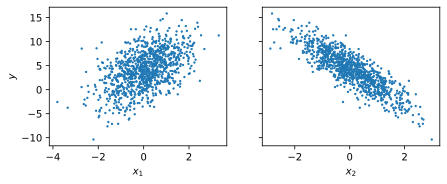

In [5]:
d2l.set_figsize((7, 2.5))
_, axes = d2l.plt.subplots(1, 2, sharey=True)
for j, ax in enumerate(axes):
    ax.scatter(d2l.numpy(X[:1000, j]), d2l.numpy(y[:1000, 0]), s=2)
    ax.set_xlabel(f'$x_{j + 1}$')
    ax.set_ylabel('$y$' if j == 0 else '')

<!-- d2l:prose id=synthetic-regression-data-md-6 fw=all -->

Each scatter plot reveals a clear linear trend with the expected sign: $y$ climbs with $x_1$ (slope $+2$) and falls more steeply with $x_2$ (slope $-3.4$). Why does each 2D scatter plot look like a thick band rather than a razor-thin line when $\sigma = 0.01$ is so tiny? Because plotting $y$ against $x_2$ alone ignores each point's variation in $x_1$: the unplotted term $2 x_1$ has standard deviation $2$, which spreads the vertical position of the points across a band several units wide. Viewing marginal 2D projections of a multivariate relationship always folds the unplotted coordinates into apparent vertical scatter.

## Recovering the Parameters

Since we derived the closed-form normal equations in that section, let us compute the exact least-squares solution $(\hat{\mathbf{w}}, \hat{b})$ on our 1,000 examples right now using `lstsq` on the augmented design matrix $[\mathbf{X}, \mathbf{1}]$. This gives us the gold-standard finite-sample fit that minibatch SGD in that section will aim to match:

In [6]:
n = 1000                                          # The training examples
X1 = torch.cat((X[:n], torch.ones(n, 1)), 1)      # A column of ones for b
w_hat = torch.linalg.lstsq(X1, y[:n]).solution[:, 0]

<!-- d2l:prose id=synthetic-regression-data-md-7 fw=all -->

Now we print the actual estimation errors alongside our predicted standard error
$\sigma / \sqrt{n}$.

In [7]:
e_w = d2l.numpy(w_hat[:2] - w_star)
print(f'error in w: ({e_w[0]:.1e}, {e_w[1]:.1e})')
print(f'error in b: {float(w_hat[2] - b_star):.1e}')
print(f'standard error: {noise / n ** 0.5:.1e}')

error in w: (3.3e-04, 5.7e-04)
error in b: 1.1e-04
standard error: 3.2e-04


<!-- d2l:prose id=synthetic-regression-data-md-8 fw=all -->

Even with `lstsq` solving the empirical loss to machine precision, $(\hat{\mathbf{w}}, \hat{b})$ differs from the true $(2, -3.4, 4.2)$ in the fourth decimal place. That tiny discrepancy is *statistical estimation error*, not numerical error: the 1,000 noise draws $\boldsymbol{\epsilon}$ happen to correlate slightly with the columns of $\mathbf{X}$, tilting the least-squares plane by a quantity of order $\sigma / \sqrt{n} = 0.01 / \sqrt{1000} \approx 3 \times 10^{-4}$ (Exercise 1). This is a limit of the data, not of the solver: no unbiased estimator computed from these 1,000 noisy points has a smaller expected squared error (the *Cramér–Rao bound*), although a single run can land closer by luck. And as Exercise 2 explores, when the true data-generating function is nonlinear, least squares finds the best linear approximation to it over the feature distribution.

## Summary

Generating synthetic data from a known linear model $\mathbf{y} = \mathbf{X}\mathbf{w}^* + b^* + \boldsymbol{\epsilon}$ with $\mathbf{w}^* = (2, -3.4)^\top$, $b^* = 4.2$, and $\sigma = 0.01$ gives us two quantitative checks that real data lack: an irreducible loss floor of $\frac{1}{2}\sigma^2 = 5 \times 10^{-5}$ and known ground-truth parameters. Plotting $y$ against a single coordinate $x_j$ folds the variation of the unplotted features into the vertical spread, turning a nearly noiseless plane into a wide 2D band. Even an exact least-squares solver deviates from $(\mathbf{w}^*, b^*)$ by statistical estimation error of order $\sigma/\sqrt{n}$ ($\approx 3 \times 10^{-4}$ for $n = 1{,}000$), setting the accuracy target for iterative optimization in the next section.

## Exercises

1. [code] **Recovery under noise.** ● Repeat the least-squares fit of
   that section on 1,000 independent
   datasets for each setting below, and measure the standard deviation of
   the estimation error $\hat{w}_1 - w_1^*$ of the first weight.
    1. Vary `noise` over $\{0.001, 0.01, 0.1, 1\}$ with 1,000 training
       examples, and the number $n$ of training examples over
       $\{10, 100, 1{,}000, 10{,}000\}$ with `noise=0.01`. Plot both measurements against the prediction
       $\sigma/\sqrt{n}$ on logarithmic axes.
    1. Find the smallest $n$ at which the measurement agrees with
       $\sigma/\sqrt{n}$ to within 10%, and say which approximation behind
       that prediction fails for fewer examples.
    1. Write $\tilde{\mathbf{X}} = [\mathbf{X}, \mathbf{1}]$,
       $\tilde{\mathbf{w}}^* = (\mathbf{w}^*, b^*)$, and
       $\hat{\tilde{\mathbf{w}}} = (\hat{\mathbf{w}}, \hat{b})$. Show from the
       normal equations that
       $\hat{\tilde{\mathbf{w}}} - \tilde{\mathbf{w}}^* = (\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}})^{-1}\tilde{\mathbf{X}}^\top\boldsymbol{\epsilon}$,
       and derive $\textrm{Cov}(\hat{\tilde{\mathbf{w}}}) = \sigma^2(\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}})^{-1}$
       from it. Then generate correlated features
       $x_2 = \rho x_1 + \sqrt{1 - \rho^2}\, z$, with $x_1$ and $z$
       independent and standard normal, for $\rho \in \{0, 0.9, 0.99\}$.
       Predict the standard error of $\hat{w}_1$ from this formula, check
       it numerically, and explain why the predictions
       $\hat{\tilde{\mathbf{w}}}^\top \tilde{\mathbf{x}}$, with $\tilde{\mathbf{x}} = (\mathbf{x}, 1)$, on new examples drawn from the same
       distribution remain accurate when the weights do not.

1. [code] **A model that does not fit.** ● Add the term $c\,x_1^2$ with
   $c = 0.5$ to every label, so that the labels no longer follow a linear
   function of the features, and fit the linear model by least squares as
   in this section.
    1. Using $\mathbb{E}[x_1^2] = 1$ and $\mathbb{E}[x_1^3] = 0$, predict
       which of $\hat{w}_1$, $\hat{w}_2$, and $\hat{b}$ end up away from
       the true values, and by about how much.
    1. Check the prediction for $n \in \{100, 1{,}000, 10{,}000\}$
       training examples. Which estimation errors shrink as $n$ grows, which
       do not, and how do the shrinking ones compare with $\sigma/\sqrt{n}$?
    1. A test that flags any parameter error above $10^{-3}$, about three
       standard errors, would pass a correct implementation on the data of
       this section. Would it declare a correct implementation faulty on
       these data? Explain what passing or failing such a test can tell you
       when the model does not fit the data.

1. **The loss floor and its fluctuation.** The next section judges a
   training run by its validation loss, the average of
   $\frac{1}{2}(\hat{y} - y)^2$ over the 1,000 validation examples.
    1. Show that a model with the true parameters has expected loss
       $\sigma^2/2$ on a new example, and that no other parameters have a
       smaller one. This is the floor that a correct training run levels
       off at.
    1. For $\epsilon \sim \mathcal{N}(0, \sigma^2)$ one has
       $\mathbb{E}[\epsilon^4] = 3\sigma^4$. Compute the standard deviation
       of the loss $\frac{1}{2}\epsilon^2$ of one example, and from it the
       standard error of the validation loss of the true parameters over
       $n' = 1{,}000$ examples, as a fraction of the floor.
    1. [code] Check both numbers by evaluating the true parameters on many
       independent validation sets. Then use the result of part (a) to find
       the smallest parameter error that raises the expected loss by one
       standard error of the validation loss, and compare it with the
       parameter-error threshold of $10^{-3}$ from the previous exercise.

<!-- d2l:prose id=synthetic-regression-data-md-9 fw=pytorch -->

[Discussions](https://d2l.discourse.group/t/6663)